In [1]:
%load_ext autoreload
%autoreload 2

# 1 IMPORT LIBRARIES

In [11]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve, auc

# 2. DATA EXPLORATION

In [16]:
data = pd.read_excel('./data/ASSURANCE VIE.xlsx', sheet_name='VIXHISTORIQUEMODEL')

In [17]:
data

,Date,SPX,VIX,VIX3M,VIX6M,VIX1Y
0,2018-06-08 16:00:00.288,2779.03,12.18,14.60,16.13,17.23
1,2018-06-11 16:00:00.288,2782.00,12.35,14.55,16.12,17.17
2,2018-06-12 16:00:00.288,2786.85,12.34,14.59,16.17,17.23
3,2018-06-13 16:00:00.288,2775.63,12.94,14.92,16.43,17.44
4,2018-06-14 16:00:00.288,2782.49,12.12,14.40,16.09,17.31
...,...,...,...,...,...,...
1596,2024-10-09 16:00:00.288,5792.04,20.86,20.91,21.85,22.55
1597,2024-10-10 16:00:00.288,5780.05,20.93,21.02,21.96,22.54
1598,2024-10-11 16:00:00.288,5815.03,20.46,20.77,21.14,22.47
1599,2024-10-14 16:00:00.288,5859.85,19.70,20.12,21.52,21.95


In [18]:
data.rename(columns={'VIX': 'VIX1M'},inplace=True)

In [19]:
data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')

In [20]:
# Set 'Date' as the index
data = data.set_index('Date')
# Ensure the index is converted to datetime format
data.index = pd.to_datetime(data.index, errors='coerce')
data = data.sort_index()
data.dropna(inplace=True)

In [21]:
data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
Date,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23
2018-06-11,2782.00,12.35,14.55,16.12,17.17
2018-06-12,2786.85,12.34,14.59,16.17,17.23
2018-06-13,2775.63,12.94,14.92,16.43,17.44
2018-06-14,2782.49,12.12,14.40,16.09,17.31
...,...,...,...,...,...
2024-10-09,5792.04,20.86,20.91,21.85,22.55
2024-10-10,5780.05,20.93,21.02,21.96,22.54
2024-10-11,5815.03,20.46,20.77,21.14,22.47


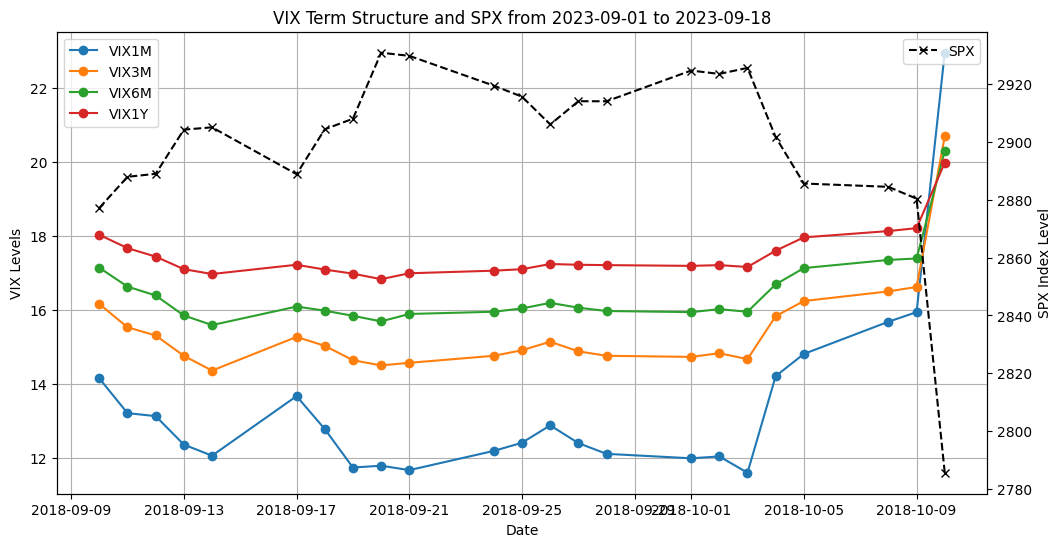

In [22]:
date_range_df = data.loc['2018-09-10':'2018-10-10']  # Filter by date range

# Create the main plot for VIX columns
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot VIX columns
ax1.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')

# Label for the VIX axis
ax1.set_ylabel("VIX Levels")
ax1.set_xlabel("Date")
ax1.legend(loc="upper left")
ax1.grid()

# Create a second y-axis for SPX
ax2 = ax1.twinx()
ax2.plot(date_range_df.index, date_range_df['SPX'], label='SPX', color='black', linestyle='--', marker='x')
ax2.set_ylabel("SPX Index Level")
ax2.legend(loc="upper right")

# Add title
plt.title("VIX Term Structure and SPX from 2023-09-01 to 2023-09-18")

plt.savefig("VIX Crash analysis.png", dpi=300, bbox_inches="tight")


NameError: name 'first_vix3m_value' is not defined

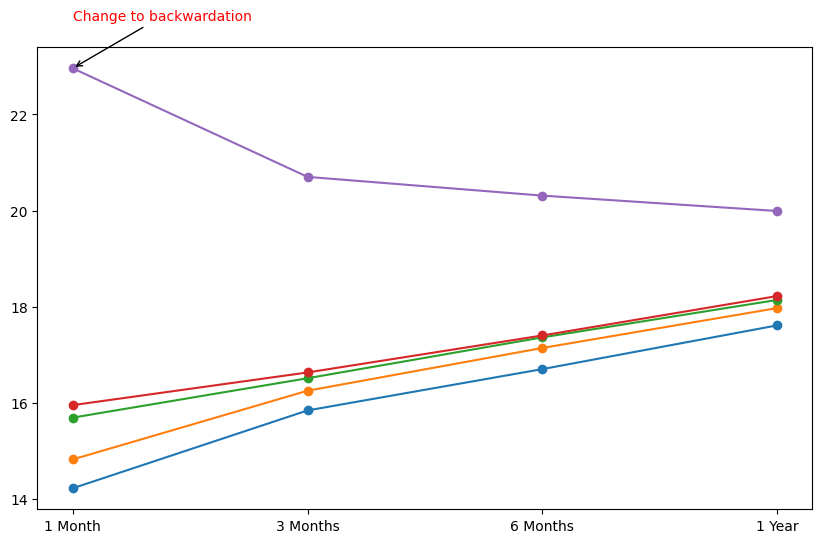

In [23]:
# Specify dates to plot the term structure for
selected_dates = ['2018-10-04', '2018-10-05', '2018-10-08', '2018-10-09', '2018-10-10']
vix_maturities = ['VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']
maturity_labels = ['1 Month', '3 Months', '6 Months', '1 Year']

# Transpose the data for easier plotting
vix_data_transposed = data.loc[selected_dates, vix_maturities].transpose()

# Plot VIX term structure with maturities as X-axis
fig, ax = plt.subplots(figsize=(10, 6))

for date in selected_dates:
    ax.plot(maturity_labels, vix_data_transposed[date], marker='o', label=f"{date}")

# Highlight the VIX1M value for the last date
last_date = selected_dates[-1]
last_vix1m_value = vix_data_transposed.loc['VIX1M', last_date]
ax.annotate(
    "Change to backwardation",  # Annotation text
    xy=('1 Month', last_vix1m_value),  # Point being annotated
    xytext=('1 Month', last_vix1m_value + 1),  # Position of the text (numeric value)
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='red'
)

ax.annotate(
    "Normal Contango structure",  # Annotation text
    xy=('3 Months', first_vix3m_value),  # Point being annotated
    xytext=('3 Months', first_vix3m_value-1 ),  # Adjust upward for text placement
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='blue'
)






# Customize plot
ax.set_xlabel("VIX Maturities")
ax.set_ylabel("VIX Levels")
ax.set_title("VIX Term Structure Across Selected Dates")
ax.legend(title="Dates")
ax.grid()

# Save and show the plot
plt.savefig("./results/VIX_Term_Structure_Maturities.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. STAGE 1 VIX SHIFT PREDICTION

In [11]:
vix_data= data.copy()

In [12]:
vix_data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
Date,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23
2018-06-11,2782.00,12.35,14.55,16.12,17.17
2018-06-12,2786.85,12.34,14.59,16.17,17.23
2018-06-13,2775.63,12.94,14.92,16.43,17.44
2018-06-14,2782.49,12.12,14.40,16.09,17.31
...,...,...,...,...,...
2024-10-09,5792.04,20.86,20.91,21.85,22.55
2024-10-10,5780.05,20.93,21.02,21.96,22.54
2024-10-14,5859.85,20.46,20.77,21.14,22.47


In [13]:
# Calculate slopes (differences) between VIX maturities
vix_data['Slope_1M_3M'] = vix_data['VIX1M'] - vix_data['VIX3M']
vix_data['Slope_3M_6M'] = vix_data['VIX3M'] - vix_data['VIX6M']
vix_data['Slope_6M_1Y'] = vix_data['VIX6M'] - vix_data['VIX1Y']

# Calculate percentage change (rate of change) over 5-day periods for each maturity
vix_data['VIX1M_Change'] = vix_data['VIX1M'].pct_change(periods=5)
vix_data['VIX3M_Change'] = vix_data['VIX3M'].pct_change(periods=5)
vix_data['VIX6M_Change'] = vix_data['VIX6M'].pct_change(periods=5)
vix_data['VIX1Y_Change'] = vix_data['VIX1Y'].pct_change(periods=5)

In [14]:
vix_data.describe()

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,VIX1M_Change,VIX3M_Change,VIX6M_Change,VIX1Y_Change
count,1593.000000,1593.000000,1593.000000,1593.000000,1593.000000,1593.000000,1593.000000,1593.000000,1588.000000,1588.000000,1588.000000,1588.000000
mean,3861.495474,20.208173,22.170352,23.430301,24.028129,-1.962178,-1.259950,-0.597828,0.014265,0.006751,0.003967,0.002321
std,835.583610,7.897525,7.005960,6.179779,5.082919,2.009303,1.539929,1.772674,0.171982,0.112469,0.081962,0.056728
min,2237.400000,10.850000,13.930000,15.410000,16.760000,-6.660000,-3.590000,-5.320000,-0.463054,-0.358351,-0.285667,-0.255124
25%,3006.790000,14.670000,16.490000,18.010000,19.400000,-2.920000,-2.100000,-1.540000,-0.081349,-0.054338,-0.039927,-0.027667
50%,3939.340000,18.450000,20.780000,22.780000,23.590000,-2.110000,-1.500000,-0.930000,-0.011091,-0.008106,-0.004913,-0.003819
75%,4438.260000,23.310000,26.100000,27.650000,28.360000,-1.230000,-0.820000,-0.200000,0.078115,0.048111,0.033563,0.026013
max,5859.850000,82.690000,72.980000,61.110000,45.860000,18.230000,13.410000,15.250000,1.516710,0.964452,0.654325,0.502153


In [15]:
# Calculate the 75th percentile (upper quartile) for each relevant column
slope_1m_3m_threshold = vix_data['Slope_1M_3M'].abs().quantile(0.75)
slope_3m_6m_threshold = vix_data['Slope_3M_6M'].abs().quantile(0.75)
slope_6m_1y_threshold = vix_data['Slope_6M_1Y'].abs().quantile(0.75)

change_1m_threshold = vix_data['VIX1M_Change'].abs().quantile(0.75)
change_3m_threshold = vix_data['VIX3M_Change'].abs().quantile(0.75)
change_6m_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)
change_1y_threshold = vix_data['VIX1Y_Change'].abs().quantile(0.75)

# Create the target variable `VIX_Significant_Change` using the calculated thresholds
vix_data['VIX_Significant_Change'] = (
    (vix_data['Slope_1M_3M'].abs() > slope_1m_3m_threshold) |
    (vix_data['Slope_3M_6M'].abs() > slope_3m_6m_threshold) |
    (vix_data['Slope_6M_1Y'].abs() > slope_6m_1y_threshold) |
    (vix_data['VIX1M_Change'].abs() > change_1m_threshold) |
    (vix_data['VIX3M_Change'].abs() > change_3m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_6m_threshold) |
    (vix_data['VIX1Y_Change'].abs() > change_1y_threshold)
).astype(int)


In [16]:
vix_data.dropna(inplace=True)

In [17]:
vix_data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,VIX1M_Change,VIX3M_Change,VIX6M_Change,VIX1Y_Change,VIX_Significant_Change
Date,,,,,,,,,,,,,
2018-06-15,2779.66,11.98,14.42,16.32,17.54,-2.44,-1.90,-1.22,-0.016420,-0.012329,0.011779,0.017992,0
2018-06-18,2773.75,12.31,14.48,16.35,17.61,-2.17,-1.87,-1.26,-0.003239,-0.004811,0.014268,0.025626,0
2018-06-19,2762.59,13.35,15.17,16.89,18.09,-1.82,-1.72,-1.20,0.081848,0.039753,0.044527,0.049913,1
2018-06-20,2767.32,12.79,14.79,16.52,17.77,-2.00,-1.73,-1.25,-0.011592,-0.008713,0.005478,0.018922,0
2018-06-21,2749.76,14.64,15.87,17.20,18.18,-1.23,-1.33,-0.98,0.207921,0.102083,0.068987,0.050260,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-09,5792.04,20.86,20.91,21.85,22.55,-0.05,-0.94,-0.70,0.103704,0.015542,0.010638,0.005350,0
2024-10-10,5780.05,20.93,21.02,21.96,22.54,-0.09,-0.94,-0.58,0.021474,-0.028202,-0.014363,-0.013998,0
2024-10-14,5859.85,20.46,20.77,21.14,22.47,-0.31,-0.37,-1.33,0.065070,0.005811,-0.021296,0.006720,0


In [18]:
vix_significant_change_sum = vix_data['VIX_Significant_Change'].sum()
print(vix_significant_change_sum)

1089


In [19]:
# Define feature set and target
X = vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']]
y = vix_data['VIX_Significant_Change']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
stage1_model = RandomForestClassifier(random_state=42)
stage1_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = stage1_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9842767295597484
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.96      0.98       116
           1       0.98      1.00      0.99       202

    accuracy                           0.98       318
   macro avg       0.99      0.98      0.98       318
weighted avg       0.98      0.98      0.98       318



# 3. STAGE 2

In [20]:
# Use the Stage 1 model to make predictions on the entire dataset
vix_data['VIX_Shift_Prediction'] = stage1_model.predict(vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 
                                                                  'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']])


In [21]:
# Display the first few rows to verify the new column
print(vix_data[['VIX_Shift_Prediction']].head())

            VIX_Shift_Prediction
Date                            
2018-06-15                     0
2018-06-18                     0
2018-06-19                     1
2018-06-20                     0
2018-06-21                     1


In [22]:
# Create lagged features of `VIX_Shift_Prediction` and any other relevant features
vix_data['VIX_Shift_Prediction_Lag1'] = vix_data['VIX_Shift_Prediction'].shift(1)
vix_data['VIX_Shift_Prediction_Lag5'] = vix_data['VIX_Shift_Prediction'].shift(5)

vix_data['VIX_Shift_Prediction_Lag2'] = vix_data['VIX_Shift_Prediction'].shift(2)
vix_data['VIX_Shift_Prediction_Lag3'] = vix_data['VIX_Shift_Prediction'].shift(3)
vix_data['VIX_Shift_Prediction_Lag4'] = vix_data['VIX_Shift_Prediction'].shift(4)

In [51]:
# Example crash flag based on a 5% drop over 5 days
CRASH_FLAG=-0.02
vix_data['SPX_5D_Change'] = vix_data['SPX'].pct_change(periods=5)
vix_data['crash_Flag'] = (vix_data['SPX_5D_Change'] <= CRASH_FLAG).astype(int)


In [52]:
# Shift the target variable 'crash_Flag' to represent the next day's crash
vix_data['Crash_Flag_Next_Day'] = vix_data['crash_Flag'].shift(-1)

# Drop rows where the next day's crash flag is NaN (e.g., the last row)
vix_data.dropna(subset=['Crash_Flag_Next_Day'], inplace=True)




In [63]:
vix_data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,VIX1M_Change,VIX3M_Change,...,VIX_Significant_Change,VIX_Shift_Prediction,VIX_Shift_Prediction_Lag1,VIX_Shift_Prediction_Lag5,VIX_Shift_Prediction_Lag2,VIX_Shift_Prediction_Lag3,VIX_Shift_Prediction_Lag4,SPX_5D_Change,crash_Flag,Crash_Flag_Next_Day
Date,,,,,,,,,,,,,,,,,,,,,
2018-06-15,2779.66,11.98,14.42,16.32,17.54,-2.44,-1.90,-1.22,-0.016420,-0.012329,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0
2018-06-18,2773.75,12.31,14.48,16.35,17.61,-2.17,-1.87,-1.26,-0.003239,-0.004811,...,0,0,0.0,NaN,NaN,NaN,NaN,NaN,0,0.0
2018-06-19,2762.59,13.35,15.17,16.89,18.09,-1.82,-1.72,-1.20,0.081848,0.039753,...,1,1,0.0,NaN,0.0,NaN,NaN,NaN,0,0.0
2018-06-20,2767.32,12.79,14.79,16.52,17.77,-2.00,-1.73,-1.25,-0.011592,-0.008713,...,0,0,1.0,NaN,0.0,0.0,NaN,NaN,0,0.0
2018-06-21,2749.76,14.64,15.87,17.20,18.18,-1.23,-1.33,-0.98,0.207921,0.102083,...,1,1,0.0,NaN,1.0,0.0,0.0,NaN,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-04,5751.07,19.21,20.65,21.60,22.32,-1.44,-0.95,-0.72,0.132665,0.056807,...,0,0,1.0,0.0,1.0,1.0,0.0,0.002248,0,0.0
2024-10-07,5695.94,22.64,22.59,23.02,23.20,0.05,-0.43,-0.18,0.353258,0.175338,...,1,1,0.0,0.0,1.0,1.0,1.0,-0.011547,0,0.0
2024-10-08,5751.13,21.42,21.52,22.45,22.80,-0.10,-0.93,-0.35,0.112150,0.030158,...,0,0,1.0,1.0,0.0,1.0,1.0,0.007424,0,0.0


In [64]:
vix_data.to_excel("./data/vix.xlsx", index=True)

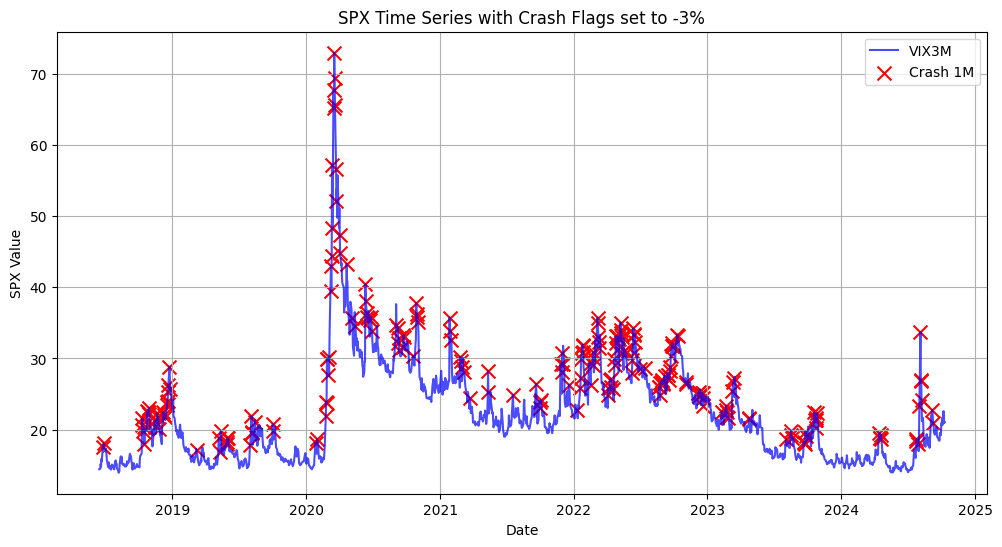

In [61]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(vix_data.index, vix_data['VIX3M'], label='VIX3M', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = vix_data[vix_data['crash_Flag'] == 1]
plt.scatter(crash_dates.index, vix_data.loc[crash_dates.index, 'VIX3M'], color='red', label='Crash 1M', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title('SPX Time Series with Crash Flags set to -3%')
plt.legend()
plt.grid(True)
plt.savefig("./results/SPX historical.png", dpi=300, bbox_inches="tight")

In [62]:
vix_data['crash_Flag'].sum()/len(vix_data)

0.14574132492113565

In [56]:
vix_data.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'Slope_1M_3M', 'Slope_3M_6M',
       'Slope_6M_1Y', 'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change',
       'VIX1Y_Change', 'VIX_Significant_Change', 'VIX_Shift_Prediction',
       'VIX_Shift_Prediction_Lag1', 'VIX_Shift_Prediction_Lag5',
       'VIX_Shift_Prediction_Lag2', 'VIX_Shift_Prediction_Lag3',
       'VIX_Shift_Prediction_Lag4', 'SPX_5D_Change', 'crash_Flag',
       'Crash_Flag_Next_Day'],
      dtype='object')

In [69]:
# List of items to remove
drop_columns = [ 'SPX','crash_Flag','Crash_Flag_Next_Day']

# Filter the list
feature_columns = [item for item in vix_data.columns if item not in drop_columns]

In [70]:
# Define features and target for Stage 2
X_stage2 = vix_data[feature_columns]
y_stage2 = vix_data['Crash_Flag_Next_Day']

# Drop rows with NaN values from lagged features
X_stage2 = X_stage2.dropna()
y_stage2 = y_stage2[X_stage2.index]

# Split into training and test sets
X_train_stage2, X_test_stage2, y_train_stage2, y_test_stage2 = train_test_split(X_stage2, y_stage2, test_size=0.2, random_state=42)



In [71]:
# Train the model
# Calculate class imbalance ratio
imbalance_ratio = len(y_train_stage2[y_train_stage2 == 0]) / len(y_train_stage2[y_train_stage2 == 1])

# Adjust the model with scale_pos_weight
stage2_model = XGBClassifier(random_state=42, scale_pos_weight=imbalance_ratio)
stage2_model.fit(X_train_stage2, y_train_stage2)

# Evaluate the model
y_pred_stage2 = stage2_model.predict(X_test_stage2)
print("Accuracy:", accuracy_score(y_test_stage2, y_pred_stage2))
print("Classification Report:\n", classification_report(y_test_stage2, y_pred_stage2))


Accuracy: 0.9240506329113924
Classification Report:
               precision    recall  f1-score   support

         0.0       0.95      0.96      0.96       270
         1.0       0.75      0.72      0.73        46

    accuracy                           0.92       316
   macro avg       0.85      0.84      0.84       316
weighted avg       0.92      0.92      0.92       316



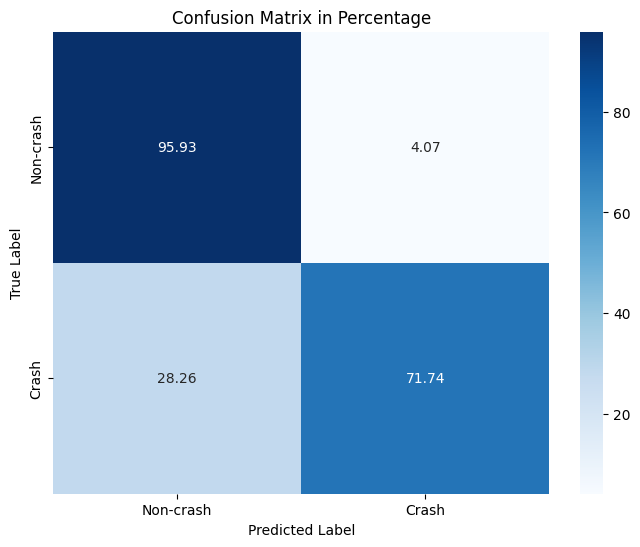

In [72]:
# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test_stage2, y_pred_stage2)

# Normalize the confusion matrix
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Plot the normalized confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_normalized * 100, annot=True, fmt='.2f', cmap='Blues', xticklabels=['Non-crash', 'Crash'], yticklabels=['Non-crash', 'Crash'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix in Percentage')

# Save the figure
plt.savefig("./results/confusion_matrix_percentage.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box
#plt.show()



No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


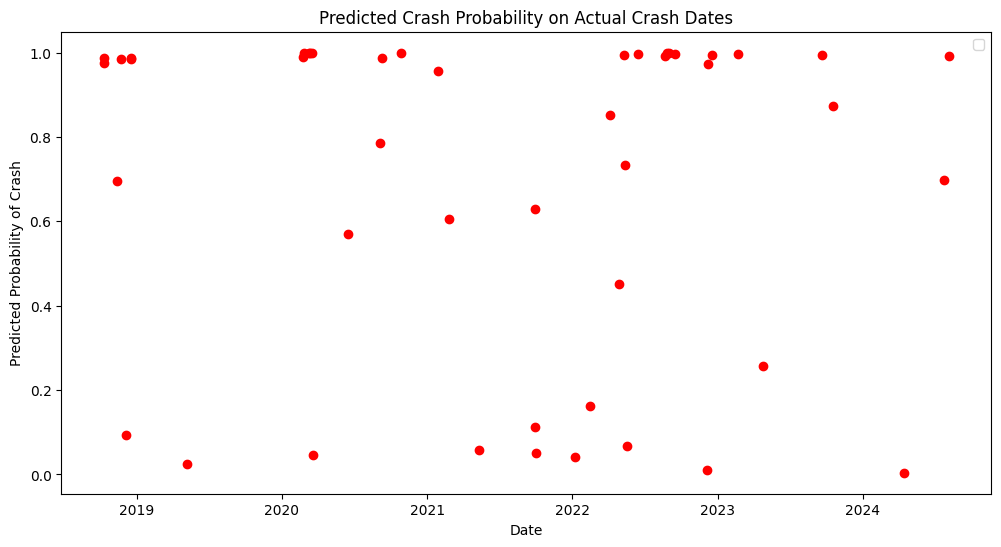

In [83]:
# Get predicted probabilities for the "crash" class (usually the second column of predict_proba output)
proba_crash = stage2_model.predict_proba(X_test_stage2)[:, 1]

# Create a DataFrame for easier plotting
results = pd.DataFrame({
    'Date': X_test_stage2.index,            # Assuming 'Date' is the index
    'Crash_Probability': proba_crash,       # Predicted probability of crash
    'Actual_Crash': y_test_stage2           # Actual crash labels
})


# Filter the data to include only the dates where a crash actually occurred
crash_dates = results[results['Actual_Crash'] == 1]

# Plot the predicted crash probabilities on actual crash dates
plt.figure(figsize=(12, 6))
plt.scatter(crash_dates['Date'], crash_dates['Crash_Probability'], color='red')
plt.xlabel('Date')
plt.ylabel('Predicted Probability of Crash')
plt.title('Predicted Crash Probability on Actual Crash Dates')
plt.legend()
#plt.show()
plt.savefig("./results/Predictions.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box


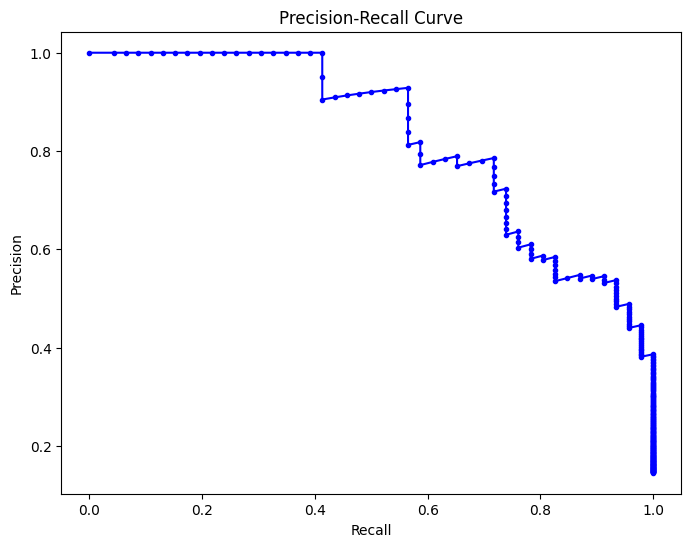

In [80]:
# Get probabilities and precision-recall data
y_probs = stage2_model.predict_proba(X_test_stage2)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test_stage2, y_probs)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', color='blue')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()


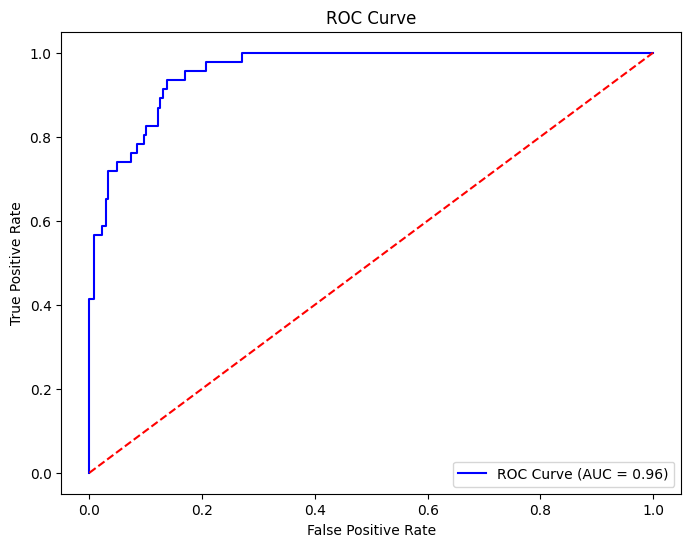

In [81]:
fpr, tpr, _ = roc_curve(y_test_stage2, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--')  # Random guessing line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()



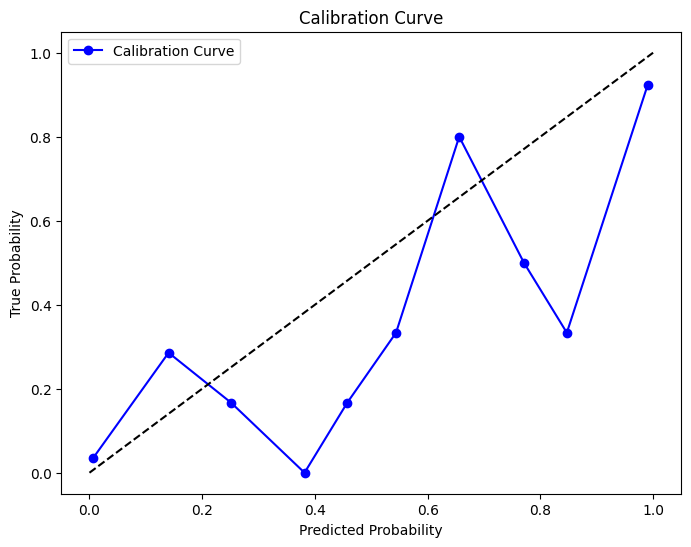

In [84]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test_stage2, y_probs, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', color='blue', label='Calibration Curve')
plt.plot([0, 1], [0, 1], 'k--')  # Perfectly calibrated line
plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')
plt.title('Calibration Curve')
plt.legend()
plt.show()


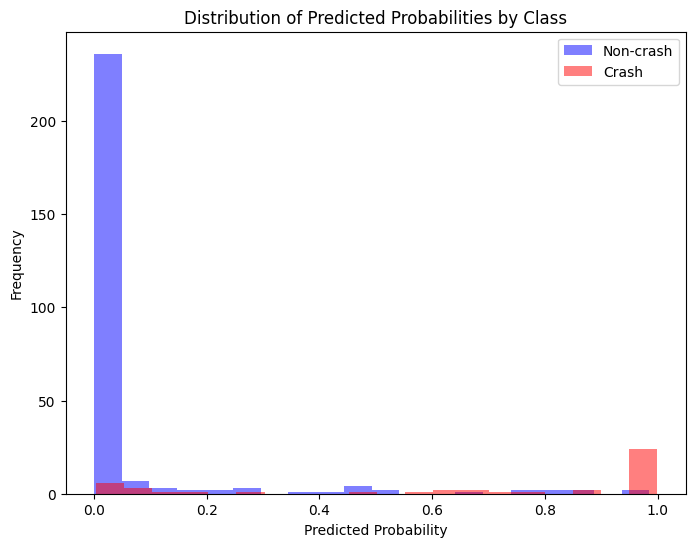

In [87]:
plt.figure(figsize=(8, 6))
plt.hist(y_probs[y_test_stage2 == 0], bins=20, alpha=0.5, label='Non-crash', color='blue')
plt.hist(y_probs[y_test_stage2 == 1], bins=20, alpha=0.5, label='Crash', color='red')
plt.xlabel('Predicted Probability')
plt.ylabel('Frequency')
plt.title('Distribution of Predicted Probabilities by Class')
plt.legend()
plt.show()




In [36]:
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(stage2_model, X_stage2, y_stage2, cv=tscv, scoring='accuracy')
print("TimeSeriesSplit Cross-Validation Accuracy Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

TimeSeriesSplit Cross-Validation Accuracy Scores: [0.88593156 0.92015209 0.82129278 0.88212928 0.92015209]
Mean CV Accuracy: 0.8859315589353611


In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming y_test_stage2 and y_pred_stage2 are available
precision = precision_score(y_test_stage2, y_pred_stage2, pos_label=1)
recall = recall_score(y_test_stage2, y_pred_stage2, pos_label=1)
f1 = f1_score(y_test_stage2, y_pred_stage2, pos_label=1)

print("Precision (Crash Class):", precision)
print("Recall (Crash Class):", recall)
print("F1-Score (Crash Class):", f1)

Precision (Crash Class): 0.6585365853658537
Recall (Crash Class): 0.6
F1-Score (Crash Class): 0.627906976744186


# 3 CREATE CRASH TARGET METRIC

In [210]:
DAY_CRASH_FLAG = -0.02  # Set crash return threshold

In [211]:
# BASIC 1 DAY RETURN TARGET
# Calculate the forward return (T+1) / T - 1
data['SPX_Fwd_Return'] = data['SPX'].shift(-1) / data['SPX'] - 1

# Create the target column based on the condition
data['Day_Crash'] = (data['SPX_Fwd_Return'] < DAY_CRASH_FLAG).astype(int)

In [212]:
# CRASH V2
CRASH_FLAG=-0.03 # return of S&P
TIME_WINDOW=20 # 4 WEEKS

# Initialize the crash_1M column with 0s
data['crash_Flag'] = 0
data['crash_start_date'] = 0
data['crash_end_date'] = 0


# Initialize a new DataFrame to store the crash flag for all dates
crash_dates_df = pd.DataFrame(data.index, columns=['Date'])
crash_dates_df['crash_flag'] = 0  # Start with all zeros
crash_dates_df.set_index('Date')
# Loop over each date in the DataFrame
for current_date in data.index:
    # Define the 1-month window
    end_date = current_date + pd.DateOffset(days=TIME_WINDOW)
    
    # Skip if the window extends beyond available data
    if end_date > data.index[-1]:
        continue
    
    # Extract SPX values within the 1-month window
    window_data = data.loc[current_date:end_date, 'SPX']
    initial_SPX= data.loc[current_date, 'SPX']
    # Check all possible returns within the window to see if any meet the crash threshold
    crash_flag = False
    for i in range(len(window_data)):
            # Calculate the return between SPX[i] and SPX[j]
        return_within_window = (window_data.iloc[i] / initial_SPX) - 1
        if return_within_window < CRASH_FLAG:
            crash_flag = True
            crash_start_date=current_date
            crash_end_date = window_data.index[i]
            break
        if crash_flag:
            break

    # If a crash is detected, set crash_1M to 1 for all dates in the 1-month window
    if crash_flag:
        data.loc[current_date, 'crash_Flag'] = 1
        data.loc[current_date, 'crash_start_date'] = crash_start_date
        data.loc[current_date, 'crash_end_date'] = crash_end_date
        # Update the crash_flag in crash_dates_df for each date in the 1-month window
        crash_dates_df.loc[crash_dates_df['Date'] == crash_start_date, 'crash_flag'] = 1
# Display the DataFrame to check the crash_1M target column
crash_dates_df.set_index('Date',inplace=True)

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_71288/1004163780.py:43: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2018-06-12 00:00:00' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[current_date, 'crash_start_date'] = crash_start_date
/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_71288/1004163780.py:44: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2018-06-27 00:00:00' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[current_date, 'crash_end_date'] = crash_end_date


In [213]:
data[data['crash_Flag'] == 1]

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,crash_start_date,crash_end_date
Date,,,,,,,,,,
2018-06-12,2786.85,12.34,14.59,16.17,17.23,-0.004026,0,1,2018-06-12 00:00:00,2018-06-27 00:00:00
2018-09-20,2930.75,11.80,14.51,15.70,16.84,-0.000369,0,1,2018-09-20 00:00:00,2018-10-10 00:00:00
2018-09-21,2929.67,11.68,14.58,15.90,17.00,-0.003516,0,1,2018-09-21 00:00:00,2018-10-10 00:00:00
2018-09-24,2919.37,12.20,14.77,15.96,17.07,-0.001305,0,1,2018-09-24 00:00:00,2018-10-10 00:00:00
2018-09-25,2915.56,12.42,14.92,16.05,17.11,-0.003289,0,1,2018-09-25 00:00:00,2018-10-10 00:00:00
...,...,...,...,...,...,...,...,...,...,...
2024-08-26,5616.84,16.15,18.25,19.36,20.27,0.001595,0,1,2024-08-26 00:00:00,2024-09-06 00:00:00
2024-08-27,5625.80,15.43,17.73,19.00,20.04,-0.005976,0,1,2024-08-27 00:00:00,2024-09-06 00:00:00
2024-08-28,5592.18,17.11,18.90,19.83,20.81,-0.000039,0,1,2024-08-28 00:00:00,2024-09-06 00:00:00


In [214]:
(len(data[data['crash_Flag'] == 1])/len(data))*100

28.185812931575644

In [215]:
(len(data[data['Day_Crash'] == 1])/len(data))*100

4.394224733207784

In [216]:
data.to_excel('./data/crash_analysis_new_2.xlsx')

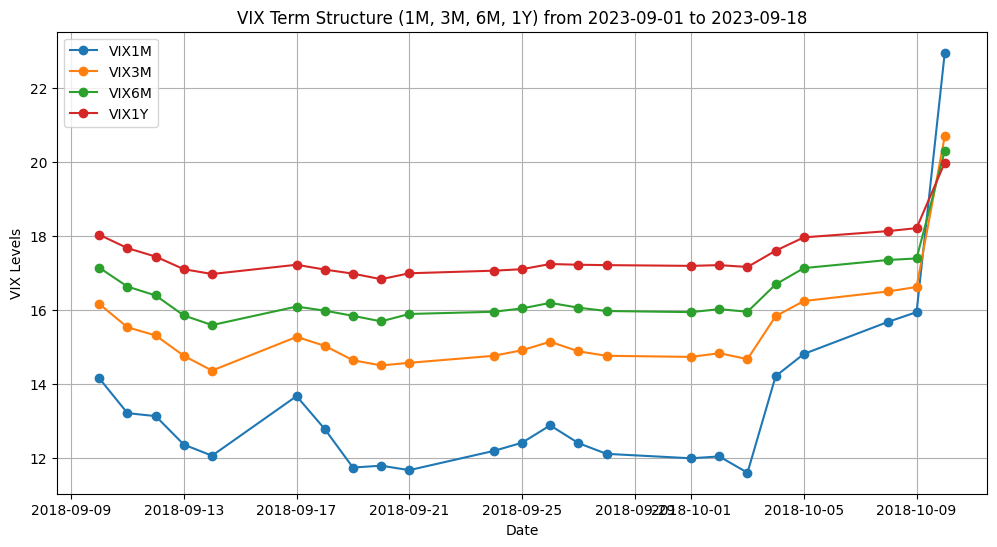

In [217]:
date_range_df = data.loc['2018-09-10':'2018-10-10']  # Filter by date range

# Plot VIX columns on the same graph
plt.figure(figsize=(12, 6))
plt.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
plt.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
plt.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
plt.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')

# Add titles and labels
plt.title("VIX Term Structure (1M, 3M, 6M, 1Y) from 2023-09-01 to 2023-09-18")
plt.xlabel("Date")
plt.ylabel("VIX Levels")
plt.legend()
plt.grid()
plt.show()


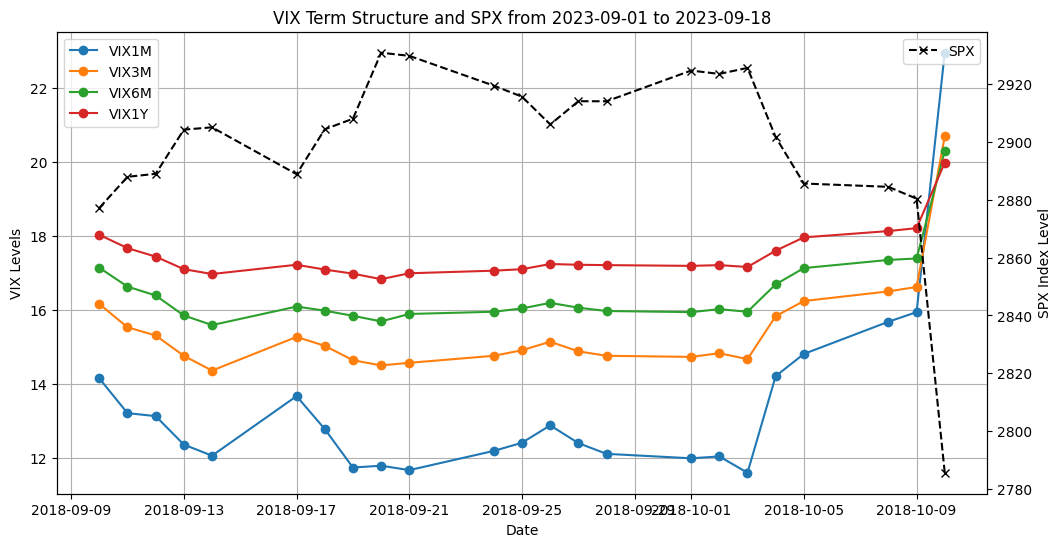

In [218]:
# Create the main plot for VIX columns
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot VIX columns
ax1.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')

# Label for the VIX axis
ax1.set_ylabel("VIX Levels")
ax1.set_xlabel("Date")
ax1.legend(loc="upper left")
ax1.grid()

# Create a second y-axis for SPX
ax2 = ax1.twinx()
ax2.plot(date_range_df.index, date_range_df['SPX'], label='SPX', color='black', linestyle='--', marker='x')
ax2.set_ylabel("SPX Index Level")
ax2.legend(loc="upper right")

# Add title
plt.title("VIX Term Structure and SPX from 2023-09-01 to 2023-09-18")

plt.show()


In [219]:
data[data['crash_Flag'] == 1].tail(50)

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,crash_start_date,crash_end_date
Date,,,,,,,,,,
2023-10-10,4358.24,17.03,18.27,20.13,22.18,0.004293,0,1,2023-10-10 00:00:00,2023-10-20 00:00:00
2023-10-11,4376.95,16.09,17.63,19.63,21.86,-0.006246,0,1,2023-10-11 00:00:00,2023-10-20 00:00:00
2023-10-12,4349.61,16.69,18.09,19.98,22.08,-0.005019,0,1,2023-10-12 00:00:00,2023-10-23 00:00:00
2023-10-13,4327.78,19.32,20.57,21.81,23.25,0.010594,0,1,2023-10-13 00:00:00,2023-10-25 00:00:00
2023-10-16,4373.63,17.21,18.79,20.64,22.62,-0.000098,0,1,2023-10-16 00:00:00,2023-10-20 00:00:00
2023-10-17,4373.20,17.88,19.26,21.06,22.93,-0.013400,0,1,2023-10-17 00:00:00,2023-10-20 00:00:00
2023-10-18,4314.60,19.22,20.47,21.96,23.55,-0.008483,0,1,2023-10-18 00:00:00,2023-10-26 00:00:00
2023-10-19,4278.00,21.40,22.19,23.21,24.39,-0.012585,0,1,2023-10-19 00:00:00,2023-10-26 00:00:00
2023-10-24,4247.68,18.97,20.21,21.85,23.47,-0.014340,0,1,2023-10-24 00:00:00,2023-10-27 00:00:00


In [220]:
# Show the probability of occurrence
proba_all = round(100 * data['crash_Flag'].value_counts().get(1, 0) / len(data), 2)
print(f"Number of crash occurrences across all period: {proba_all}%")



Number of crash occurrences across all period: 28.19%


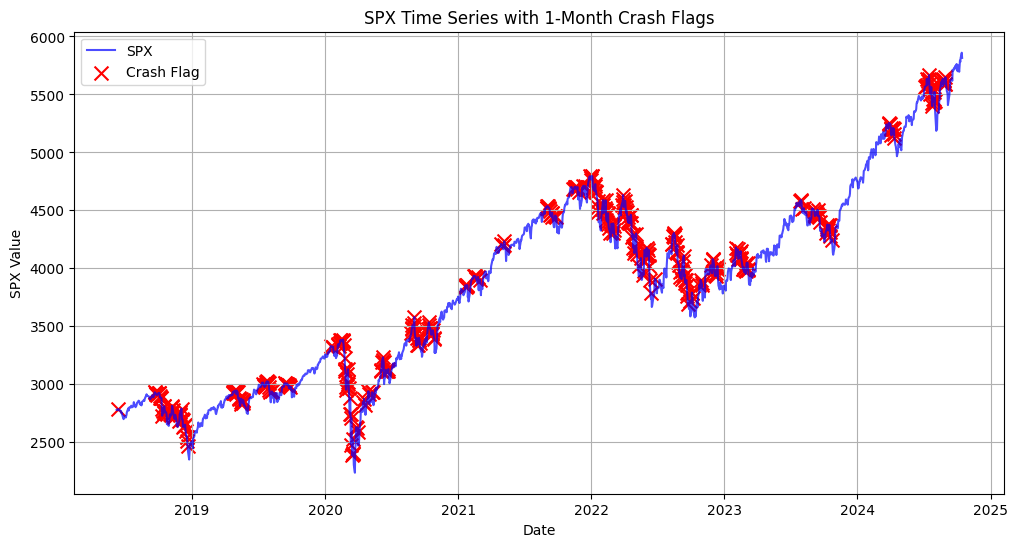

In [221]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['SPX'], label='SPX', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = crash_dates_df[crash_dates_df['crash_flag'] == 1]
plt.scatter(crash_dates.index, data.loc[crash_dates.index, 'SPX'], color='red', label='Crash Flag', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title('SPX Time Series with 1-Month Crash Flags')
plt.legend()
plt.grid(True)
plt.show()

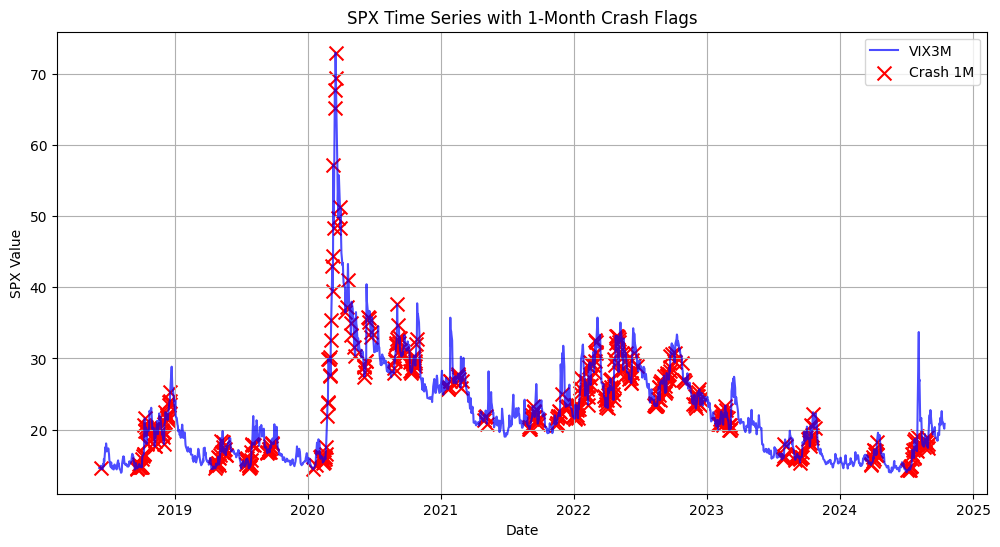

In [222]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['VIX3M'], label='VIX3M', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = crash_dates_df[crash_dates_df['crash_flag'] == 1]
plt.scatter(crash_dates.index, data.loc[crash_dates.index, 'VIX3M'], color='red', label='Crash 1M', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title('SPX Time Series with 1-Month Crash Flags')
plt.legend()
plt.grid(True)
plt.show()

# 4 DATA FEATURISATION

In [170]:
data.dropna(inplace=True)

# 4.1 LOG TRANFORMATION

In [236]:
data.columns
# Step 1: Create pairwise differences
data['1M3M'] = data['VIX3M'] /data['VIX1M']
data['3M6M'] = data['VIX6M'] /data['VIX3M']
data['6M1Y'] = data['VIX1Y'] /data['VIX6M']
data['VIXSteep1M6M'] = data['3M6M'] /data['1M3M']
data['VIXSteep3M1Y'] = data['6M1Y'] /data['3M6M']

In [237]:
feature_columns=['SPX','VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', '1M3M', '3M6M', '6M1Y','VIXSteep1M6M', 'VIXSteep3M1Y']

In [243]:
log_transformed_data = pd.DataFrame(index=data.index)
log_transformed_data['Crash'] = data['crash_Flag']
for col in feature_columns:
    # Apply log transformation
    log_transformed_data[f'log_{col}'] = np.log(data[col])
    
    # Calculate log variations (log differences)
    log_transformed_data[f'log_variation_{col}'] = log_transformed_data[f'log_{col}'].diff()
    # Calculate second-order log differences (second-order derivative of log variations)
    log_transformed_data[f'second_order_derivative_{col}'] = log_transformed_data[f'log_variation_{col}'].diff()

In [244]:
log_transformed_data.dropna(inplace=True)

In [245]:
log_transformed_data.columns

Index(['Crash', 'log_SPX', 'log_variation_SPX', 'second_order_derivative_SPX',
       'log_VIX1M', 'log_variation_VIX1M', 'second_order_derivative_VIX1M',
       'log_VIX3M', 'log_variation_VIX3M', 'second_order_derivative_VIX3M',
       'log_VIX6M', 'log_variation_VIX6M', 'second_order_derivative_VIX6M',
       'log_VIX1Y', 'log_variation_VIX1Y', 'second_order_derivative_VIX1Y',
       'log_1M3M', 'log_variation_1M3M', 'second_order_derivative_1M3M',
       'log_3M6M', 'log_variation_3M6M', 'second_order_derivative_3M6M',
       'log_6M1Y', 'log_variation_6M1Y', 'second_order_derivative_6M1Y',
       'log_VIXSteep1M6M', 'log_variation_VIXSteep1M6M',
       'second_order_derivative_VIXSteep1M6M', 'log_VIXSteep3M1Y',
       'log_variation_VIXSteep3M1Y', 'second_order_derivative_VIXSteep3M1Y'],
      dtype='object')

In [246]:
log_features=['log_SPX', 'log_variation_SPX', 'log_VIX1M',
       'log_variation_VIX1M', 'log_VIX3M', 'log_variation_VIX3M', 'log_VIX6M',
       'log_variation_VIX6M', 'log_VIX1Y', 'log_variation_VIX1Y', 'log_1M3M',
       'log_variation_1M3M', 'log_3M6M', 'log_variation_3M6M', 'log_6M1Y',
       'log_variation_6M1Y']

In [247]:
# Define the maximum number of lags to calculate changes from T-1
max_lag = 5  # Adjust as needed

# Calculate changes from T-1 backward for each variable
for lag in range(2, max_lag + 1):  # Start from T-2
    for col in log_features:
        # Calculate change from T-1 to T-lag
        log_transformed_data[f'{col}_Change_T1_to_T{lag}'] = log_transformed_data[col].shift(1) - log_transformed_data[col].shift(lag)


In [248]:
log_transformed_data.dropna(inplace=True)

In [249]:
log_transformed_data

,Crash,log_SPX,log_variation_SPX,second_order_derivative_SPX,log_VIX1M,log_variation_VIX1M,second_order_derivative_VIX1M,log_VIX3M,log_variation_VIX3M,second_order_derivative_VIX3M,...,log_VIX6M_Change_T1_to_T5,log_variation_VIX6M_Change_T1_to_T5,log_VIX1Y_Change_T1_to_T5,log_variation_VIX1Y_Change_T1_to_T5,log_1M3M_Change_T1_to_T5,log_variation_1M3M_Change_T1_to_T5,log_3M6M_Change_T1_to_T5,log_variation_3M6M_Change_T1_to_T5,log_6M1Y_Change_T1_to_T5,log_variation_6M1Y_Change_T1_to_T5
Date,,,,,,,,,,,,,,,,,,,,,
2018-06-19,0,7.923924,-0.004032,-0.001903,2.591516,0.081104,0.053931,2.719320,0.046551,0.042399,...,0.011070,-0.001260,0.021815,0.000495,-0.005134,-0.026577,0.018638,-0.002667,0.010745,0.001755
2018-06-20,0,7.925635,0.001711,0.005742,2.548664,-0.042853,-0.123957,2.693951,-0.025369,-0.071920,...,0.027613,0.016543,0.036593,0.014778,-0.014576,-0.009442,0.010996,-0.007643,0.008980,-0.001765
2018-06-21,0,7.919269,-0.006366,-0.008076,2.683758,0.135094,0.177947,2.764431,0.070479,0.095848,...,0.026374,-0.001239,0.026227,-0.010366,-0.027084,-0.012508,-0.000349,-0.011345,-0.000147,-0.009127
2018-06-22,0,7.921129,0.001860,0.008226,2.622492,-0.061265,-0.196359,2.740840,-0.023591,-0.094070,...,0.052518,0.026144,0.035838,0.009611,-0.104705,-0.077621,-0.043296,-0.042947,-0.016680,-0.016533
2018-06-25,0,7.907309,-0.013820,-0.015680,2.852439,0.229947,0.291212,2.863343,0.122503,0.146094,...,0.034268,-0.018250,0.028549,-0.007289,-0.044009,0.060696,-0.033803,0.009493,-0.005719,0.010961
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-09,0,8.664240,0.007088,-0.002555,3.037833,-0.026492,0.028902,3.040228,-0.028755,0.019769,...,0.037672,-0.015406,0.016361,-0.007190,-0.080986,0.002465,-0.006505,0.018653,-0.021311,0.008217
2024-10-10,0,8.662168,-0.002072,-0.009160,3.041184,0.003350,0.029842,3.045474,0.005247,0.034002,...,-0.019488,-0.057160,-0.013654,-0.030015,-0.051750,0.029236,0.014365,0.020871,0.005835,0.027146
2024-10-11,0,8.668201,0.006034,0.008106,3.018472,-0.022712,-0.026062,3.033510,-0.011965,-0.017212,...,0.016529,0.036018,0.009808,0.023462,-0.067994,-0.016243,-0.001230,-0.015595,-0.006721,-0.012556


In [250]:
log_transformed_data.describe()

,Crash,log_SPX,log_variation_SPX,second_order_derivative_SPX,log_VIX1M,log_variation_VIX1M,second_order_derivative_VIX1M,log_VIX3M,log_variation_VIX3M,second_order_derivative_VIX3M,...,log_VIX6M_Change_T1_to_T5,log_variation_VIX6M_Change_T1_to_T5,log_VIX1Y_Change_T1_to_T5,log_variation_VIX1Y_Change_T1_to_T5,log_1M3M_Change_T1_to_T5,log_variation_1M3M_Change_T1_to_T5,log_3M6M_Change_T1_to_T5,log_variation_3M6M_Change_T1_to_T5,log_6M1Y_Change_T1_to_T5,log_variation_6M1Y_Change_T1_to_T5
count,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,...,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000,1586.000000
mean,0.282472,8.236388,0.000467,-0.000003,2.950096,0.000326,0.000012,3.058432,0.000228,0.000018,...,0.000726,-0.000046,0.000637,-0.000037,-0.000394,-0.000003,-0.000158,-0.000009,-0.000089,0.000008
std,0.450344,0.218891,0.012740,0.019454,0.324113,0.077366,0.114784,0.280620,0.049642,0.072902,...,0.069433,0.051829,0.049010,0.036874,0.056871,0.046153,0.028575,0.022450,0.026272,0.022292
min,0.000000,7.713070,-0.127652,-0.216460,2.384165,-0.330681,-0.830848,2.634045,-0.230886,-0.598512,...,-0.384816,-0.368072,-0.339136,-0.268102,-0.299687,-0.207321,-0.173371,-0.106227,-0.173116,-0.131444
25%,0.000000,8.010800,-0.004744,-0.008479,2.689377,-0.043869,-0.055439,2.805479,-0.027107,-0.032145,...,-0.036566,-0.024077,-0.025346,-0.016364,-0.029101,-0.027480,-0.013755,-0.012171,-0.011484,-0.010251
50%,0.000000,8.279547,0.000860,-0.000482,2.917230,-0.008132,0.003166,3.034232,-0.004873,0.001956,...,-0.004994,0.001649,-0.002905,0.000539,0.003679,-0.001020,0.002806,-0.000838,0.002066,-0.000834
75%,1.000000,8.398650,0.006846,0.007592,3.149526,0.034665,0.059867,3.262893,0.020988,0.035151,...,0.031405,0.025302,0.021973,0.017878,0.031899,0.025482,0.016143,0.011421,0.013864,0.009910
max,1.000000,8.675879,0.089683,0.188753,4.415099,0.500166,0.623819,4.290185,0.367626,0.507062,...,0.478269,0.367043,0.327112,0.238711,0.230031,0.261585,0.119042,0.129953,0.157748,0.149541


In [251]:
drop_columns=['Crash']

In [252]:
X=log_transformed_data.drop(columns=drop_columns)

In [253]:
y=log_transformed_data['Crash']

In [254]:
100*y.value_counts().get(1, 0)/len(y)

28.247162673392182

# 4.2. STANDARD FEATURING NO LOG

In [223]:
data_featured= data.copy()

In [224]:
data_featured

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,crash_start_date,crash_end_date
Date,,,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,0.001069,0,0,0,0
2018-06-11,2782.00,12.35,14.55,16.12,17.17,0.001743,0,0,0,0
2018-06-12,2786.85,12.34,14.59,16.17,17.23,-0.004026,0,1,2018-06-12 00:00:00,2018-06-27 00:00:00
2018-06-13,2775.63,12.94,14.92,16.43,17.44,0.002472,0,0,0,0
2018-06-14,2782.49,12.12,14.40,16.09,17.31,-0.001017,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
2024-10-09,5792.04,20.86,20.91,21.85,22.55,-0.002070,0,0,0,0
2024-10-10,5780.05,20.93,21.02,21.96,22.54,0.006052,0,0,0,0
2024-10-11,5815.03,20.46,20.77,21.76,22.47,0.007708,0,0,0,0


In [225]:
# Adding VIX term structure features
data_featured['Slope_1M_3M'] = data_featured['VIX1M'] - data_featured['VIX3M']  # Slope between VIX1M and VIX1Y
data_featured['Slope_3M_6M'] = data_featured['VIX3M'] - data_featured['VIX6M']  # Slope between VIX1M and VIX6M
data_featured['Slope_6M_1Y'] = data_featured['VIX6M'] - data_featured['VIX1Y']  # Slope between VIX3M and VIX1Y
#data_featured['Spread_1M_3M'] = data_featured['VIX1M'] / data_featured['VIX3M']  # Spread ratio between VIX1M and VIX3M
#data_featured['Spread_3M_6M'] = data_featured['VIX3M'] / data_featured['VIX6M']  # Spread ratio between VIX3M and VIX6M

# Rate of change in Slope_1M_1Y for volatility shifts
#data_featured['Slope_1M_1Y_Change'] = data_featured['Slope_1M_1Y'].pct_change()
# SPX percentage change to capture day-over-day changes
data_featured['SPX_Pct_Change'] = data_featured['SPX'].pct_change()

# Rolling windows for SPX changes to capture short-term trends (e.g., 5-day and 10-day moving averages)
data_featured['SPX_5D_Change'] = data_featured['SPX'].pct_change(periods=5)
data_featured['SPX_10D_Change'] = data_featured['SPX'].pct_change(periods=10)

# Volatility measure using the rolling standard deviation of SPX returns over a 10-day window
data_featured['SPX_10D_Volatility'] = data_featured['SPX_Pct_Change'].rolling(window=10).std()



# Reset the index if needed, especially after dropping rows
#data_featured.reset_index(drop=True, inplace=True)

# Display the modified DataFrame
data_featured.head()


,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,crash_start_date,crash_end_date,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility
Date,,,,,,,,,,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,0.001069,0,0,0,0,-2.42,-1.53,-1.10,NaN,NaN,NaN,NaN
2018-06-11,2782.00,12.35,14.55,16.12,17.17,0.001743,0,0,0,0,-2.20,-1.57,-1.05,0.001069,NaN,NaN,NaN
2018-06-12,2786.85,12.34,14.59,16.17,17.23,-0.004026,0,1,2018-06-12 00:00:00,2018-06-27 00:00:00,-2.25,-1.58,-1.06,0.001743,NaN,NaN,NaN
2018-06-13,2775.63,12.94,14.92,16.43,17.44,0.002472,0,0,0,0,-1.98,-1.51,-1.01,-0.004026,NaN,NaN,NaN
2018-06-14,2782.49,12.12,14.40,16.09,17.31,-0.001017,0,0,0,0,-2.28,-1.69,-1.22,0.002472,NaN,NaN,NaN


In [226]:
print(data_featured.head())


                SPX  VIX1M  VIX3M  VIX6M  VIX1Y  SPX_Fwd_Return  Day_Crash  \
Date                                                                         
2018-06-08  2779.03  12.18  14.60  16.13  17.23        0.001069          0   
2018-06-11  2782.00  12.35  14.55  16.12  17.17        0.001743          0   
2018-06-12  2786.85  12.34  14.59  16.17  17.23       -0.004026          0   
2018-06-13  2775.63  12.94  14.92  16.43  17.44        0.002472          0   
2018-06-14  2782.49  12.12  14.40  16.09  17.31       -0.001017          0   

            crash_Flag     crash_start_date       crash_end_date  Slope_1M_3M  \
Date                                                                            
2018-06-08           0                    0                    0        -2.42   
2018-06-11           0                    0                    0        -2.20   
2018-06-12           1  2018-06-12 00:00:00  2018-06-27 00:00:00        -2.25   
2018-06-13           0                    0     

In [227]:
data_featured.dropna(inplace=True)

In [228]:
data_featured.describe()

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility
count,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000
mean,3867.117895,20.255360,22.217939,23.476201,24.070228,0.000553,0.044248,0.283186,-1.962579,-1.258262,-0.594027,0.000559,0.002678,0.005286,0.010284
std,832.502911,7.902044,7.005341,6.175596,5.074071,0.012705,0.205710,0.450688,2.015571,1.544608,1.778176,0.012703,0.025757,0.035840,0.007691
min,2237.400000,10.850000,13.930000,15.410000,16.760000,-0.119841,0.000000,0.000000,-6.660000,-3.590000,-5.320000,-0.119841,-0.179666,-0.233863,0.002457
25%,3015.615000,14.740000,16.560000,18.042500,19.480000,-0.004733,0.000000,0.000000,-2.940000,-2.100000,-1.547500,-0.004722,-0.008844,-0.011089,0.005845
50%,3944.675000,18.490000,20.790000,22.865000,23.665000,0.000861,0.000000,0.000000,-2.110000,-1.500000,-0.920000,0.000874,0.005132,0.009725,0.008486
75%,4441.067500,23.345000,26.167500,27.717500,28.405000,0.006877,0.000000,1.000000,-1.230000,-0.820000,-0.192500,0.006877,0.016540,0.025874,0.012560
max,5859.850000,82.690000,72.980000,61.110000,45.860000,0.093828,1.000000,1.000000,18.230000,13.410000,15.250000,0.093828,0.173974,0.190525,0.074826


In [229]:
data_featured.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'SPX_Fwd_Return',
       'Day_Crash', 'crash_Flag', 'crash_start_date', 'crash_end_date',
       'Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 'SPX_Pct_Change',
       'SPX_5D_Change', 'SPX_10D_Change', 'SPX_10D_Volatility'],
      dtype='object')

In [230]:
data_featured['1M3M_SLOPE_CHANGE'] = data_featured['Slope_1M_3M'].diff() / data_featured['VIX1M']
data_featured['3M6M_SLOPE_CHANGE'] = data_featured['Slope_3M_6M'].diff() / data_featured['VIX3M']
data_featured['6M1Y_SLOPE_CHANGE'] = data_featured['Slope_6M_1Y'].diff() / data_featured['VIX6M']

In [231]:
data_featured.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'SPX_Fwd_Return',
       'Day_Crash', 'crash_Flag', 'crash_start_date', 'crash_end_date',
       'Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 'SPX_Pct_Change',
       'SPX_5D_Change', 'SPX_10D_Change', 'SPX_10D_Volatility',
       '1M3M_SLOPE_CHANGE', '3M6M_SLOPE_CHANGE', '6M1Y_SLOPE_CHANGE'],
      dtype='object')

In [232]:
# List of items to remove
drop_columns = ['crash_Flag', 'Day_Crash', 'crash_start_date','crash_end_date','SPX_Fwd_Return']

# Filter the list
feature_columns = [item for item in data_featured.columns if item not in drop_columns]

In [233]:
feature_columns

['SPX',
 'VIX1M',
 'VIX3M',
 'VIX6M',
 'VIX1Y',
 'Slope_1M_3M',
 'Slope_3M_6M',
 'Slope_6M_1Y',
 'SPX_Pct_Change',
 'SPX_5D_Change',
 'SPX_10D_Change',
 'SPX_10D_Volatility',
 '1M3M_SLOPE_CHANGE',
 '3M6M_SLOPE_CHANGE',
 '6M1Y_SLOPE_CHANGE']

In [234]:
data_featured

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,crash_start_date,crash_end_date,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility,1M3M_SLOPE_CHANGE,3M6M_SLOPE_CHANGE,6M1Y_SLOPE_CHANGE
Date,,,,,,,,,,,,,,,,,,,,
2018-06-22,2754.88,13.77,15.50,16.92,18.12,-0.013725,0,0,0,0,-1.73,-1.42,-1.20,0.001862,-0.008915,-0.008690,0.003116,NaN,NaN,NaN
2018-06-25,2717.07,17.33,17.52,18.27,18.87,0.002205,0,0,0,0,-0.19,-0.75,-0.60,-0.013725,-0.020434,-0.023339,0.005022,0.088863,0.038242,0.032841
2018-06-26,2723.06,15.92,16.87,17.79,18.49,-0.008604,0,0,0,0,-0.95,-0.92,-0.70,0.002205,-0.014309,-0.022890,0.005066,-0.047739,-0.010077,-0.005621
2018-06-27,2699.63,17.91,18.05,18.66,18.99,0.006179,0,0,0,0,-0.14,-0.61,-0.33,-0.008604,-0.024460,-0.027381,0.005433,0.045226,0.017175,0.019829
2018-06-28,2716.31,16.85,17.52,18.29,18.78,0.000758,0,0,0,0,-0.67,-0.77,-0.49,0.006179,-0.012165,-0.023784,0.005933,-0.031454,-0.009132,-0.008748
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-08,5751.13,21.42,21.52,22.45,22.80,0.007113,0,0,0,0,-0.10,-0.93,-0.35,0.009689,0.007424,0.003175,0.006618,-0.007003,-0.023234,-0.007572
2024-10-09,5792.04,20.86,20.91,21.85,22.55,-0.002070,0,0,0,0,-0.05,-0.94,-0.70,0.007113,0.014450,0.012194,0.006890,0.002397,-0.000478,-0.016018
2024-10-10,5780.05,20.93,21.02,21.96,22.54,0.006052,0,0,0,0,-0.09,-0.94,-0.58,-0.002070,0.014055,0.006036,0.006884,-0.001911,0.000000,0.005464


In [235]:
data_featured.describe()

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Day_Crash,crash_Flag,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility,1M3M_SLOPE_CHANGE,3M6M_SLOPE_CHANGE,6M1Y_SLOPE_CHANGE
count,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1581.000000,1581.000000,1581.000000
mean,3867.117895,20.255360,22.217939,23.476201,24.070228,0.000553,0.044248,0.283186,-1.962579,-1.258262,-0.594027,0.000559,0.002678,0.005286,0.010284,-0.000698,-0.000209,-0.000163
std,832.502911,7.902044,7.005341,6.175596,5.074071,0.012705,0.205710,0.450688,2.015571,1.544608,1.778176,0.012703,0.025757,0.035840,0.007691,0.028917,0.014639,0.016052
min,2237.400000,10.850000,13.930000,15.410000,16.760000,-0.119841,0.000000,0.000000,-6.660000,-3.590000,-5.320000,-0.119841,-0.179666,-0.233863,0.002457,-0.150614,-0.083333,-0.095461
25%,3015.615000,14.740000,16.560000,18.042500,19.480000,-0.004733,0.000000,0.000000,-2.940000,-2.100000,-1.547500,-0.004722,-0.008844,-0.011089,0.005845,-0.016667,-0.007847,-0.007439
50%,3944.675000,18.490000,20.790000,22.865000,23.665000,0.000861,0.000000,0.000000,-2.110000,-1.500000,-0.920000,0.000874,0.005132,0.009725,0.008486,-0.001429,-0.001352,-0.001098
75%,4441.067500,23.345000,26.167500,27.717500,28.405000,0.006877,0.000000,1.000000,-1.230000,-0.820000,-0.192500,0.006877,0.016540,0.025874,0.012560,0.013757,0.006276,0.006014
max,5859.850000,82.690000,72.980000,61.110000,45.860000,0.093828,1.000000,1.000000,18.230000,13.410000,15.250000,0.093828,0.173974,0.190525,0.074826,0.145425,0.091071,0.145256


In [184]:
data_featured.dropna(inplace=True)

In [185]:
X= data_featured.drop(columns=drop_columns)

In [186]:
y=data_featured['crash_Flag']

# 5 IMPLEMENT MODEL

In [255]:
scaler=StandardScaler()

In [256]:
X_scaled=pd.DataFrame(scaler.fit_transform(X),columns=X.columns)

In [257]:
X_scaled

,log_SPX,log_variation_SPX,second_order_derivative_SPX,log_VIX1M,log_variation_VIX1M,second_order_derivative_VIX1M,log_VIX3M,log_variation_VIX3M,second_order_derivative_VIX3M,log_VIX6M,...,log_VIX6M_Change_T1_to_T5,log_variation_VIX6M_Change_T1_to_T5,log_VIX1Y_Change_T1_to_T5,log_variation_VIX1Y_Change_T1_to_T5,log_1M3M_Change_T1_to_T5,log_variation_1M3M_Change_T1_to_T5,log_3M6M_Change_T1_to_T5,log_variation_3M6M_Change_T1_to_T5,log_6M1Y_Change_T1_to_T5,log_variation_6M1Y_Change_T1_to_T5
0,-1.427937,-0.353210,-0.097681,-1.106691,1.044443,0.469892,-1.208820,0.933437,0.581526,-1.193018,...,0.149024,-0.023444,0.432242,0.014431,-0.083372,-0.575944,0.657984,-0.118452,0.412489,0.078380
1,-1.420119,0.097674,0.295448,-1.238948,-0.558287,-1.080369,-1.299251,-0.515792,-0.987097,-1.282056,...,0.387351,0.320157,0.733867,0.401913,-0.249451,-0.204575,0.390442,-0.340144,0.345303,-0.079555
2,-1.449210,-0.536489,-0.415114,-0.822006,1.742510,1.550662,-1.048016,1.415597,1.314918,-1.119908,...,0.369501,-0.023031,0.522301,-0.280184,-0.469452,-0.271020,-0.006703,-0.505110,-0.002194,-0.409922
3,-1.440709,0.109417,0.423161,-1.011090,-0.796354,-1.711336,-1.132108,-0.479964,-1.291025,-1.185885,...,0.746157,0.505471,0.718462,0.261737,-1.834750,-1.682269,-1.510137,-1.913254,-0.631704,-0.742296
4,-1.503864,-1.121787,-0.806097,-0.301401,2.968929,2.537746,-0.695426,2.463908,2.004363,-0.877311,...,0.483238,-0.351339,0.569696,-0.196714,-0.767154,1.315574,-1.177812,0.423399,-0.214369,0.491488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1581,1.955250,0.519919,-0.131176,0.270785,-0.346742,0.251765,-0.064892,-0.584036,0.271013,-0.158012,...,0.532269,-0.296466,0.320930,-0.194032,-1.417557,0.053498,-0.222209,0.831550,-0.808018,0.368342
1582,1.945780,-0.199363,-0.470855,0.281124,0.039102,0.259958,-0.046189,0.101126,0.466306,-0.137826,...,-0.291231,-1.102324,-0.291683,-0.813227,-0.903321,0.633716,0.508402,0.930359,0.225550,1.217763
1583,1.973353,0.437112,0.416985,0.211028,-0.297870,-0.227231,-0.088839,-0.245698,-0.236419,-0.174604,...,0.227673,0.696033,0.187185,0.637491,-1.189029,-0.351985,-0.037526,-0.694489,-0.252514,-0.563806
1584,2.008441,0.566235,0.084737,0.094202,-0.493643,-0.132061,-0.202178,-0.645296,-0.272356,-0.290801,...,-0.821424,-1.404546,-0.665553,-1.132383,0.310324,1.847590,0.975477,1.289803,0.929325,1.392513


In [258]:
# Define the split point for 80-20
split_point = int(len(data_featured) * 0.8)

# Split the data
X_train = X_scaled.iloc[:split_point]  # First 80% for training
X_test = X_scaled.iloc[split_point:]   # Last 20% for testing
y_train= y.iloc[:split_point]  # First 80% for training
y_test=y.iloc[split_point:]   # Last 20% for testing

# Display split sizes
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
y_benchmark = data['SPX'].iloc[split_point:]

Training set size: 1265
Test set size: 321


In [259]:
# Show the probability of occurrence
proba_train= round(100*y_train.value_counts().get(1, 0)/len(y_train), 2)
proba_test = round(100*y_test.value_counts().get(1, 0)/len(y_test), 2)
print(f"Number of crash occurrences across in train: {proba_train}%")
print(f"Number of crash occurrences across in test: {proba_test}%")

Number of crash occurrences across in train: 29.88%
Number of crash occurrences across in test: 21.81%


# 5.1 LASSO FOR FEATURE SELECTION

In [260]:
# Create a scorer for recall
recall_scorer = make_scorer(recall_score)

In [261]:
# Pipeline to standardize data and apply Logistic Regression with L1 regularization
lasso_logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Standardize features
    ('lasso', LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42))  # L1 regularization
])
lasso_logreg_pipeline.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()),
  ('lasso',
   LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear'))],
 'verbose': False,
 'scaler': StandardScaler(),
 'lasso': LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear'),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'lasso__C': 0.1,
 'lasso__class_weight': None,
 'lasso__dual': False,
 'lasso__fit_intercept': True,
 'lasso__intercept_scaling': 1,
 'lasso__l1_ratio': None,
 'lasso__max_iter': 100,
 'lasso__multi_class': 'deprecated',
 'lasso__n_jobs': None,
 'lasso__penalty': 'l1',
 'lasso__random_state': 42,
 'lasso__solver': 'liblinear',
 'lasso__tol': 0.0001,
 'lasso__verbose': 0,
 'lasso__warm_start': False}

In [262]:


# Define the hyperparameters to search over (here, tuning the regularization parameter C)
param_grid = {
    'lasso__C': [1, 10,100]  # Adjust as needed
}

# Set up GridSearchCV to optimize for recall
grid_search = GridSearchCV(lasso_logreg_pipeline, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Best model and its recall
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
best_recall = recall_score(y_test, y_pred)

print(f"Best Recall: {best_recall:.2f}")
print(f"Best Parameters: {grid_search.best_params_}")

Best Recall: 0.49
Best Parameters: {'lasso__C': 1}


In [263]:
# Get feature names and coefficients
feature_names = X.columns
coefficients = best_model.named_steps['lasso'].coef_[0]

# Select features with non-zero coefficients
selected_features = feature_names[coefficients != 0]
print("Selected features:", selected_features)

Selected features: Index(['log_SPX', 'log_variation_SPX', 'log_VIX1Y', 'log_3M6M',
       'log_variation_3M6M', 'log_VIXSteep1M6M', 'log_variation_VIXSteep1M6M',
       'log_VIXSteep3M1Y', 'log_variation_VIXSteep3M1Y',
       'log_variation_SPX_Change_T1_to_T2', 'log_VIX1Y_Change_T1_to_T2',
       'log_1M3M_Change_T1_to_T2', 'log_variation_6M1Y_Change_T1_to_T2',
       'log_variation_SPX_Change_T1_to_T3', 'log_VIX6M_Change_T1_to_T3',
       'log_VIX1Y_Change_T1_to_T3', 'log_1M3M_Change_T1_to_T3',
       'log_3M6M_Change_T1_to_T3', 'log_variation_SPX_Change_T1_to_T4',
       'log_VIX1Y_Change_T1_to_T4', 'log_3M6M_Change_T1_to_T4',
       'log_variation_6M1Y_Change_T1_to_T4', 'log_SPX_Change_T1_to_T5',
       'log_variation_SPX_Change_T1_to_T5', 'log_VIX1Y_Change_T1_to_T5',
       'log_variation_VIX1Y_Change_T1_to_T5', 'log_1M3M_Change_T1_to_T5',
       'log_variation_1M3M_Change_T1_to_T5', 'log_3M6M_Change_T1_to_T5',
       'log_variation_3M6M_Change_T1_to_T5', 'log_6M1Y_Change_T1_to_T5

In [273]:
coefficients

array([ 0.63778825, -0.08789817,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        , -0.04029653,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        , -0.50747876,  0.21874226,
        0.        ,  0.        ,  0.        ,  0.        , -0.04260781,
        0.16377268,  0.        ,  0.52458694, -0.02330443,  0.        ,
        0.        , -0.17166049,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.12811845,  0.        ,
       -0.00739024,  0.        ,  0.        ,  0.        ,  0.        ,
        0.07331567,  0.        ,  0.11673005,  0.        ,  0.        ,
        0.        ,  0.        ,  0.3288155 ,  0.        ,  0.00788911,
        0.        , -0.00659688,  0.        ,  0.22792492,  0.        ,
        0.        ,  0.        ,  0.        ,  0.17170646,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.  

In [264]:
# Make predictions
y_pred = best_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy:", accuracy)

Model accuracy: 0.4485981308411215


In [265]:
# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

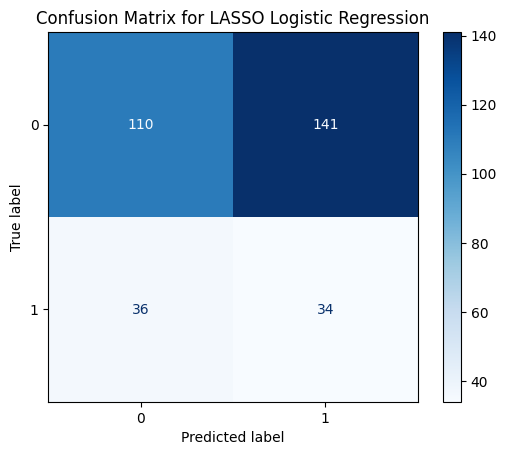

In [266]:
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for LASSO Logistic Regression")
plt.show()


# 5.2 XGB CLASSIFIER MODEL

In [267]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy='minority', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

In [268]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'n_estimators': [500],           # 2 values
    'max_depth': [3, 5],                  # 2 values
    'learning_rate': [0.01],         # 2 values
    'subsample': [0.8],                   # 1 value
    'colsample_bytree': [0.8],            # 1 value
    'gamma': [0.1],                       # 1 value
    'scale_pos_weight': [1, 5, 10]        # 3 values
}

# Initialize XGBClassifier
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

# Set up GridSearchCV with recall as scoring to focus on crash events
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='recall',         # Optimize for recall to capture crashes
    cv=5,                     # Cross-validation
    n_jobs=-1,
    verbose=1
)

# Fit grid search
grid_search.fit(X_train, y_train)

# Get the best estimator and parameters
best_model = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)


Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'colsample_bytree': 0.8, 'gamma': 0.1, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500, 'scale_pos_weight': 10, 'subsample': 0.8}
Best Score: 0.6893684210526315


In [270]:
# Step 5: Make predictions and evaluate the model
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]  # Probability of crash (1)

# Print evaluation metrics
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[181  70]
 [ 46  24]]

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.72      0.76       251
           1       0.26      0.34      0.29        70

    accuracy                           0.64       321
   macro avg       0.53      0.53      0.53       321
weighted avg       0.68      0.64      0.66       321



In [1]:
y_prob

NameError: name 'y_prob' is not defined

In [272]:
threshold = 0.3  # Default is 0.5
y_pred_adjusted = (y_prob >= threshold).astype(int)
print("\nConfusion Matrix with Adjusted Threshold:\n", confusion_matrix(y_test, y_pred_adjusted))
print("\nClassification Report with Adjusted Threshold:\n", classification_report(y_test, y_pred_adjusted))


Confusion Matrix with Adjusted Threshold:
 [[ 84 167]
 [ 22  48]]

Classification Report with Adjusted Threshold:
               precision    recall  f1-score   support

           0       0.79      0.33      0.47       251
           1       0.22      0.69      0.34        70

    accuracy                           0.41       321
   macro avg       0.51      0.51      0.40       321
weighted avg       0.67      0.41      0.44       321



In [70]:


# Assuming `y_test` and `y_pred` are Series or arrays and `X_test` has a Date index
# Convert `y_test` and `y_pred` to DataFrames if necessary
y_test = pd.Series(y_test, index=X_test.index, name='Actual')
y_pred = pd.Series(y_pred, index=X_test.index, name='Predicted')
y_prod= pd.Series(y_prob, index=X_test.index, name='Proba')
# Combine into a single DataFrame for comparison
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred, 'Proba':y_prob})

# Identify mismatches where `Actual` is not equal to `Predicted`
mismatch_dates = results[results['Actual'] != results['Predicted']]
matching_dates = results[(results['Actual'] == 1) & (results['Predicted'] == 1)]
# Display the mismatched dates and their values
print("Dates with mismatches between Actual and Predicted:")
print(mismatch_dates)

print("Dates with matches between Actual and Predicted:")
print(matching_dates)



Dates with mismatches between Actual and Predicted:
      Actual  Predicted     Proba
1260     NaN          0  0.094476
1261     NaN          0  0.091031
1262     NaN          0  0.069854
1263     NaN          0  0.082324
1264     NaN          0  0.087112
...      ...        ...       ...
1571     NaN          0  0.196208
1572     NaN          0  0.187087
1573     NaN          0  0.117599
1574     NaN          0  0.160322
1575     NaN          0  0.115877

[316 rows x 3 columns]
Dates with matches between Actual and Predicted:
Empty DataFrame
Columns: [Actual, Predicted, Proba]
Index: []


In [37]:
# Initialize the `predicted_adjusted` column with 0s
results['proba_adjusted'] =df['Proba']

NameError: name 'df' is not defined

In [38]:
# Loop over each date in the DataFrame where Proba > 0.5
for current_date in results[results['Proba'] > 0.5].index:
    # Define the 1-month window (30 days)
    end_date = current_date + pd.DateOffset(days=30)
    
    # Set `predicted_adjusted` to 1 for each day in the window
    results.loc[current_date:end_date, 'proba_adjusted'] = results.loc[current_date:end_date, 'Proba']
results['proba_adjusted'].fillna(0, inplace=True)
print(results[['Proba', 'proba_adjusted']])

TypeError: unsupported operand type(s) for +: 'int' and 'DateOffset'

In [171]:
df=results.copy()

In [172]:
df[df['proba_adjusted']>0.5]

,Actual,Predicted,Proba,predicted_adjusted,proba_adjusted
Date,,,,,
2023-07-18,0,1,0.507828,0,0.507828
2023-08-04,0,1,0.849204,0,0.849204
2023-08-15,0,1,0.506772,0,0.506772
2023-08-17,0,1,0.752270,0,0.752270
2023-09-21,0,1,0.850702,0,0.850702
...,...,...,...,...,...
2024-10-08,0,1,0.806104,0,0.806104
2024-10-09,0,1,0.807900,0,0.807900
2024-10-10,0,1,0.818717,0,0.818717


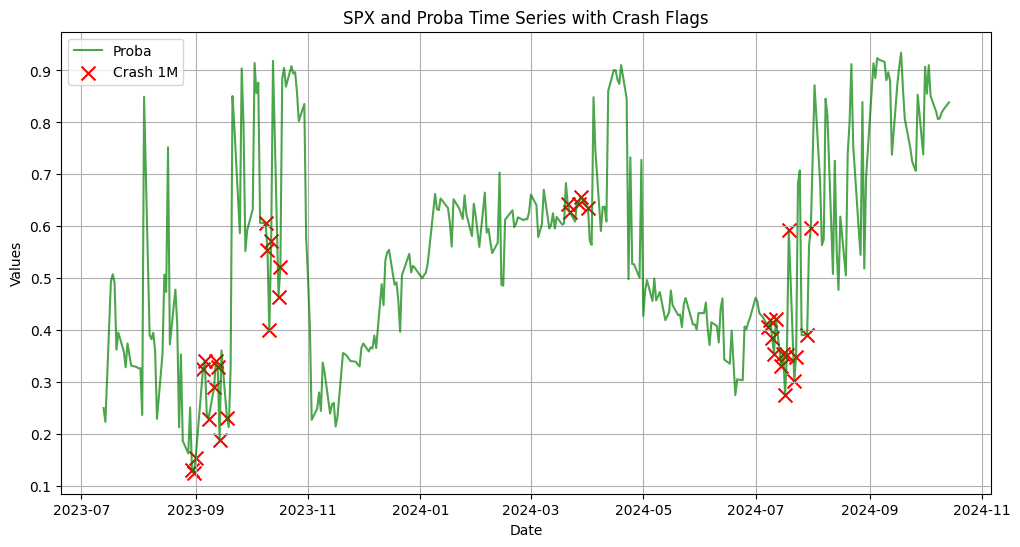

In [173]:
# Ensure both DataFrames have datetime indices
df.index = pd.to_datetime(df.index)
#data.index = pd.to_datetime(data.index)

# Plot SPX and Proba time series
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['proba_adjusted'], label='Proba', color='green', alpha=0.7)
#plt.plot(data.index, data['SPX'], label='SPX', color='blue', alpha=0.7)

# Filter Proba values to match crash dates
crash_dates = crash_dates_df[crash_dates_df['crash_flag'] > 0.5]
proba_crash_values = df.loc[df.index.intersection(crash_dates.index), 'proba_adjusted']

# Plot the crash dates with matching Proba values
plt.scatter(proba_crash_values.index, proba_crash_values, color='red', label='Crash 1M', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('Values')
plt.title('SPX and Proba Time Series with Crash Flags')
plt.legend()
plt.grid(True)
plt.show()


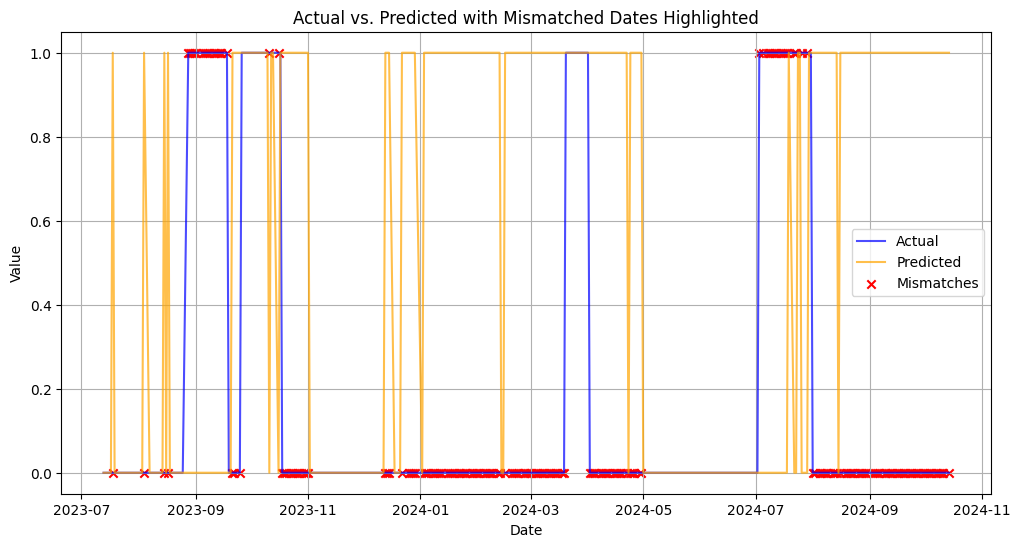

In [174]:
import matplotlib.pyplot as plt
# Plot the entire time series of Actual and Predicted values for context
plt.figure(figsize=(12, 6))
plt.plot(results.index, results['Actual'], label='Actual', color='blue', alpha=0.7)
plt.plot(results.index, results['Predicted'], label='Predicted', color='orange', alpha=0.7)

# Highlight mismatched dates
plt.scatter(mismatch_dates.index, mismatch_dates['Actual'], color='red', label='Mismatches', marker='x')

# Customize plot
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Actual vs. Predicted with Mismatched Dates Highlighted')
plt.legend()
plt.grid(True)
plt.show()

In [67]:
import pandas as pd

# Convert the index to DateTime if it's not already in that format
results.index = pd.to_datetime(results.index)

# Example time frame: 2 days before and after each prediction
time_frame = pd.Timedelta(days=30)

# Create a new column to flag true predictions
results['True_Flag'] = 0

# Iterate over rows where y_pred = 1
for index, row in results[results['Predicted'] == 1].iterrows():
    # Define the time window around the prediction date
    start_date = index 
    end_date = index + time_frame
    
    # Check if any actual `1` occurs within the time window
    if (results['Actual'].loc[start_date:end_date] == 1).any():
        results.at[index, 'True_Flag'] = 1  # Flag as true prediction if condition is met

# Display the results with the True_Flag column
print(results[['Actual', 'Predicted', 'True_Flag']])


            Actual  Predicted  True_Flag
Date                                    
2023-07-13       0          0          0
2023-07-14       0          0          0
2023-07-17       0          0          0
2023-07-18       0          0          0
2023-07-19       0          0          0
...            ...        ...        ...
2024-10-08       0          1          0
2024-10-09       0          1          0
2024-10-10       0          1          0
2024-10-11       0          1          0
2024-10-14       0          1          0

[317 rows x 3 columns]


In [68]:
# Identify mismatches where `Actual` is not equal to `Predicted`
mismatch_dates = results[results['Actual'] != results['True_Flag']]
matching_dates = results[(results['Actual'] == 1) & (results['True_Flag'] == 1)]
# Display the mismatched dates and their values
print("Dates with mismatches between Actual and Predicted:")
print(mismatch_dates)

print("Dates with matches between Actual and Predicted:")
print(matching_dates)


Dates with mismatches between Actual and Predicted:
            Actual  Predicted     Proba  True_Flag
Date                                              
2023-08-04       0          1  0.909578          1
2023-08-17       0          1  0.906695          1
2023-08-18       0          1  0.716988          1
2023-08-21       0          1  0.646898          1
2023-08-22       0          1  0.598133          1
...            ...        ...       ...        ...
2024-07-18       1          0  0.382690          0
2024-07-22       1          0  0.485382          0
2024-07-23       1          0  0.417846          0
2024-08-27       1          0  0.453867          0
2024-08-29       1          0  0.405437          0

[71 rows x 4 columns]
Dates with matches between Actual and Predicted:
            Actual  Predicted     Proba  True_Flag
Date                                              
2023-09-21       1          1  0.939378          1
2023-09-22       1          1  0.937330          1
2023-09-2

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate probabilities for the positive class (crash = 1)
#y_prob = logreg.predict_proba(X_test)[:, 1]

# Calculate the ROC curve points
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate the AUC score
auc_score = roc_auc_score(y_test, y_prob)
print(f"AUC Score: {auc_score:.4f}")

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Dashed line for random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


/Users/alamazou/.pyenv/versions/d1quantenv/lib/python3.10/site-packages/sklearn/utils/_array_api.py:390: RuntimeWarning: invalid value encountered in cast
  return x.astype(dtype, copy=copy, casting=casting)


ValueError: Input y_true contains NaN.

In [72]:
# Calculate True Positives and False Positives
true_positives = results[(results['Predicted'] == 1) & (results['True_Flag'] == 1)].shape[0]
false_positives = results[(results['Predicted'] == 1) & (results['True_Flag'] == 0)].shape[0]

# Calculate precision
precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0

# Display the precision
print(f"Adjusted Precision: {precision:.4f}")


KeyError: 'True_Flag'

In [71]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

# Use 'weight', 'gain', or 'cover' to see different aspects of feature importance
plot_importance(best_model, importance_type='gain')  # Gain is often more informative
plt.title("Feature Importance by Gain")
plt.show()

ValueError: tree must be Booster, XGBModel or dict instance

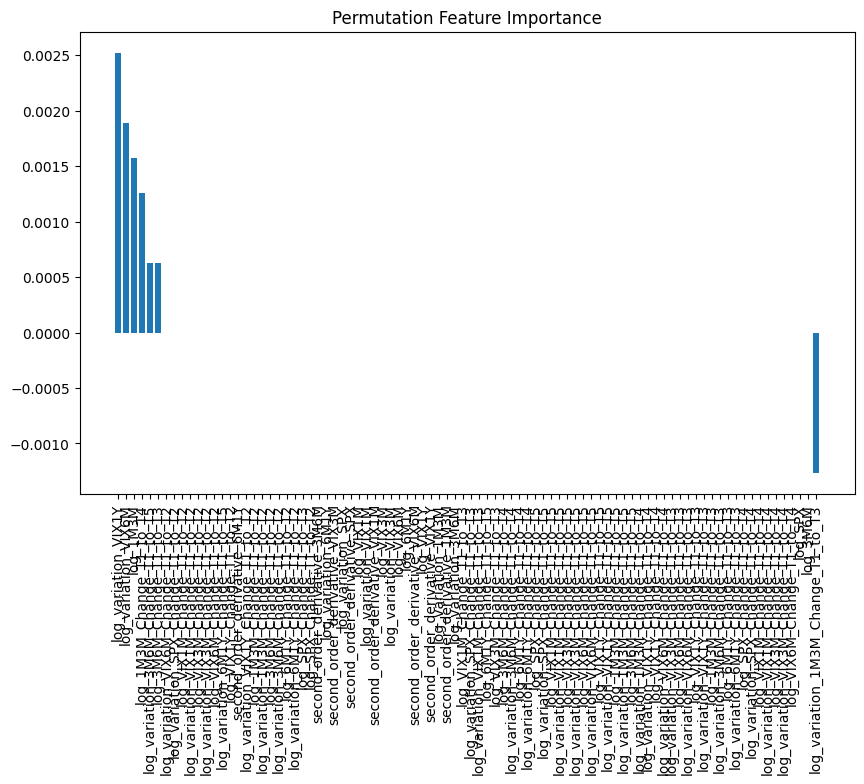

In [142]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
sorted_indices = result.importances_mean.argsort()[::-1]

# Plot permutation importance
plt.figure(figsize=(10, 6))
plt.bar(range(len(X_test.columns)), result.importances_mean[sorted_indices], tick_label=X_test.columns[sorted_indices])
plt.xticks(rotation=90)
plt.title("Permutation Feature Importance")
plt.show()


In [26]:


# Assuming `model` is your trained XGBClassifier and `X_train` is the training DataFrame

# Get feature importance scores based on 'gain'
feature_importance = model.get_booster().get_score(importance_type='gain')

# Convert to a DataFrame for easier manipulation
importance_df = pd.DataFrame(
    list(feature_importance.items()), columns=['Feature', 'Importance']
)

# Sort features by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Calculate cumulative importance
importance_df['Cumulative Importance'] = importance_df['Importance'].cumsum() / importance_df['Importance'].sum()

# Filter features that contribute up to 90% of the importance
top_features = importance_df[importance_df['Cumulative Importance'] <= 0.8]['Feature'].tolist()

# Display the selected features
print("Top features explaining 90% of the model:", top_features)


Top features explaining 90% of the model: ['6M1Y', '3M6M_Change_T1_to_T4', 'VIX6M_Change_T1_to_T2', 'VIX1M', 'SPX_Change_T1_to_T4', 'SPX_Change_T1_to_T5', 'VIX3M_Change_T1_to_T2', 'VIX6M', '3M6M', 'VIX6M_Change_T1_to_T5', '1M3M_Change_T1_to_T5', '1M3M', '3M6M_Change_T1_to_T2', 'SPX_Change_T1_to_T2', '6M1Y_Change_T1_to_T4', 'SPX_Change_T1_to_T3']


In [217]:
import numpy as np

Final Benchmark Return: 1.2893663013046082
Final Strategy Return: 1.2795793225393712


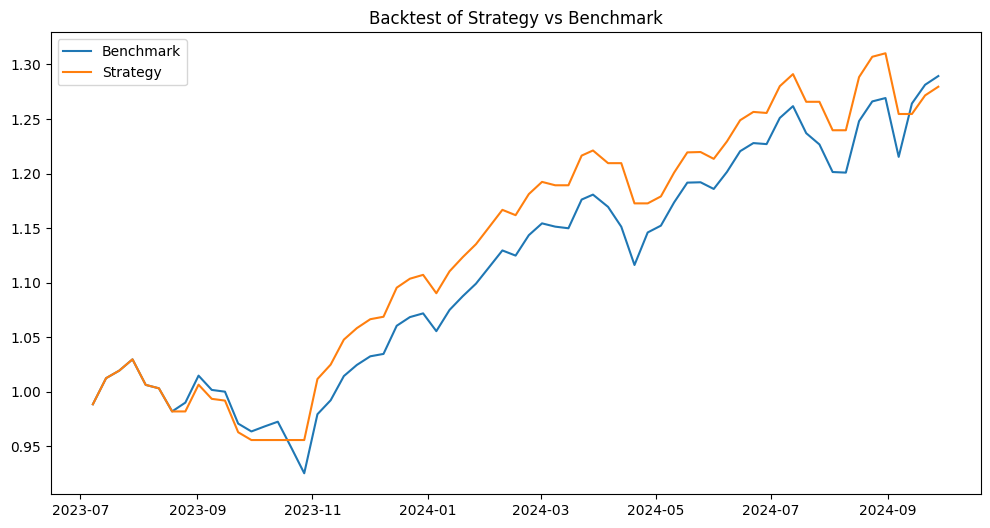

In [218]:

# Assume `X_test` is your test set features, `y_test` is the actual target values, 
# and `y_pred` is the predicted target values from the model.

# Get model predictions (assuming `model` is trained)
y_pred = model.predict(X_test)

# Create a DataFrame for backtesting
backtest_data = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Benchmark': y_benchmark  # Replace 'y' with the actual column name for the benchmark series
})

# Strategy - Sell when crash is predicted (Predicted == 1), otherwise hold
backtest_data['Position'] = np.where(backtest_data['Predicted'] == 1, 0, 1)

# Calculate Returns
backtest_data['Benchmark_Returns'] = backtest_data['Benchmark'].pct_change()  # Daily returns of benchmark
backtest_data['Strategy_Returns'] = backtest_data['Benchmark_Returns'] * backtest_data['Position'].shift(1)

# Calculate Cumulative Returns for Benchmark and Strategy
backtest_data['Benchmark_Cumulative'] = (1 + backtest_data['Benchmark_Returns']).cumprod()
backtest_data['Strategy_Cumulative'] = (1 + backtest_data['Strategy_Returns']).cumprod()

# Display results
print("Final Benchmark Return:", backtest_data['Benchmark_Cumulative'].iloc[-1])
print("Final Strategy Return:", backtest_data['Strategy_Cumulative'].iloc[-1])



plt.figure(figsize=(12, 6))
plt.plot(backtest_data['Benchmark_Cumulative'], label='Benchmark')
plt.plot(backtest_data['Strategy_Cumulative'], label='Strategy')
plt.legend()
plt.title("Backtest of Strategy vs Benchmark")
plt.show()


In [223]:


# Calculate benchmark returns if not already calculated
backtest_data['Benchmark_Returns'] = backtest_data['Benchmark'].pct_change()

# Calculate Volatility (Standard Deviation of Returns)
benchmark_volatility = backtest_data['Benchmark_Returns'].std() * np.sqrt(52)  # Annualized volatility
strategy_volatility = backtest_data['Strategy_Returns'].std() * np.sqrt(52)    # Annualized volatility

# Display results
print("Benchmark Volatility (Annualized):", benchmark_volatility)
print("Strategy Volatility (Annualized):", strategy_volatility)


Benchmark Volatility (Annualized): 0.12965633005796817
Strategy Volatility (Annualized): 0.11682605228420234


In [225]:
backtest_data

,Actual,Predicted,Benchmark,Position,Benchmark_Returns,Strategy_Returns,Benchmark_Cumulative,Strategy_Cumulative
Date,,,,,,,,
2023-06-30 16:00:00,0,0,4450.38,1,NaN,NaN,NaN,NaN
2023-07-07 16:00:00,1,0,4398.95,1,-0.011556,-0.011556,0.988444,0.988444
2023-07-14 16:00:00,0,0,4505.42,1,0.024204,0.024204,1.012367,1.012367
2023-07-21 16:00:00,0,0,4536.34,1,0.006863,0.006863,1.019315,1.019315
2023-07-28 16:00:00,0,0,4582.23,1,0.010116,0.010116,1.029627,1.029627
...,...,...,...,...,...,...,...,...
2024-08-30 16:00:00,0,0,5648.40,1,0.002447,0.002447,1.269195,1.310238
2024-09-06 16:00:00,1,1,5408.42,0,-0.042486,-0.042486,1.215272,1.254571
2024-09-13 16:00:00,0,0,5626.02,1,0.040234,0.000000,1.264166,1.254571


In [221]:
from sklearn.ensemble import IsolationForest

# Train Isolation Forest on normal data only if possible
model = IsolationForest(contamination=0.1, random_state=42)  # Adjust contamination based on crash frequency
model.fit(X_resampled)

# Predict anomalies in the test set
y_pred = model.predict(X_test)
y_pred = [1 if x == -1 else 0 for x in y_pred]  # Convert -1 (anomaly) to 1 (crash), and 1 (normal) to 0

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Confusion Matrix:
 [[48  5]
 [13  0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.91      0.84        53
           1       0.00      0.00      0.00        13

    accuracy                           0.73        66
   macro avg       0.39      0.45      0.42        66
weighted avg       0.63      0.73      0.68        66



In [166]:
# Initialize the Logistic Regression model
logreg = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)

# Fit the model on the training data
logreg.fit(X_resampled, y_resampled)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [167]:
# Predict class labels
y_pred = logreg.predict(X_test)

# Predict probabilities
y_prob = logreg.predict_proba(X_test)[:, 1]  # Probability of the crash class (1)

In [169]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, recall_score
# Print classification report
print("Classification Report:\n", classification_report(y_test, y_pred))

# Confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Recall score
recall = recall_score(y_test, y_pred)
print(f"Recall Score: {recall:.4f}")

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.70      0.78       280
           1       0.11      0.27      0.15        37

    accuracy                           0.65       317
   macro avg       0.49      0.49      0.47       317
weighted avg       0.79      0.65      0.71       317

Confusion Matrix:
 [[196  84]
 [ 27  10]]
Recall Score: 0.2703
